In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from utils.models import *
from utils.dataloader import *
from utils.utils_sig import *
from utils.Loss import *


In [2]:
def calculate_batch_mae(preds, targets, fs=30):
    
    mae_sum = 0.0
    valid_count = 0
    
    # GPU 텐서를 CPU 넘파이 배열로 변
    
    # 2. FFT 기반 HR 추출
    pred_hr, _, _ = hr_fft(preds, fs)
    gt_hr, _, _ = hr_fft(targets, fs)
    
    mae = abs(pred_hr - gt_hr)
            
    return mae

def z_norm_per_sample(x):
    # x: (B, T)
    mean = x.mean(dim=-1, keepdim=True)   # (B, 1)
    std  = x.std(dim=-1, keepdim=True)    # (B, 1)
    return (x - mean) / (std + 1e-8)      # per-sample


모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_driving_withoutoutlier_len300_gtsubjectznorm/final_dataset_subject4_garage_large_motion_975_uv.h5']
rPPG: (300,), GT: (300,)


/tmp/ipykernel_1995636/832935183.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



💾 Saved: /home/son/orientation-uv-rppg/data/pics/time_freq_domain_10s_zeropad.png


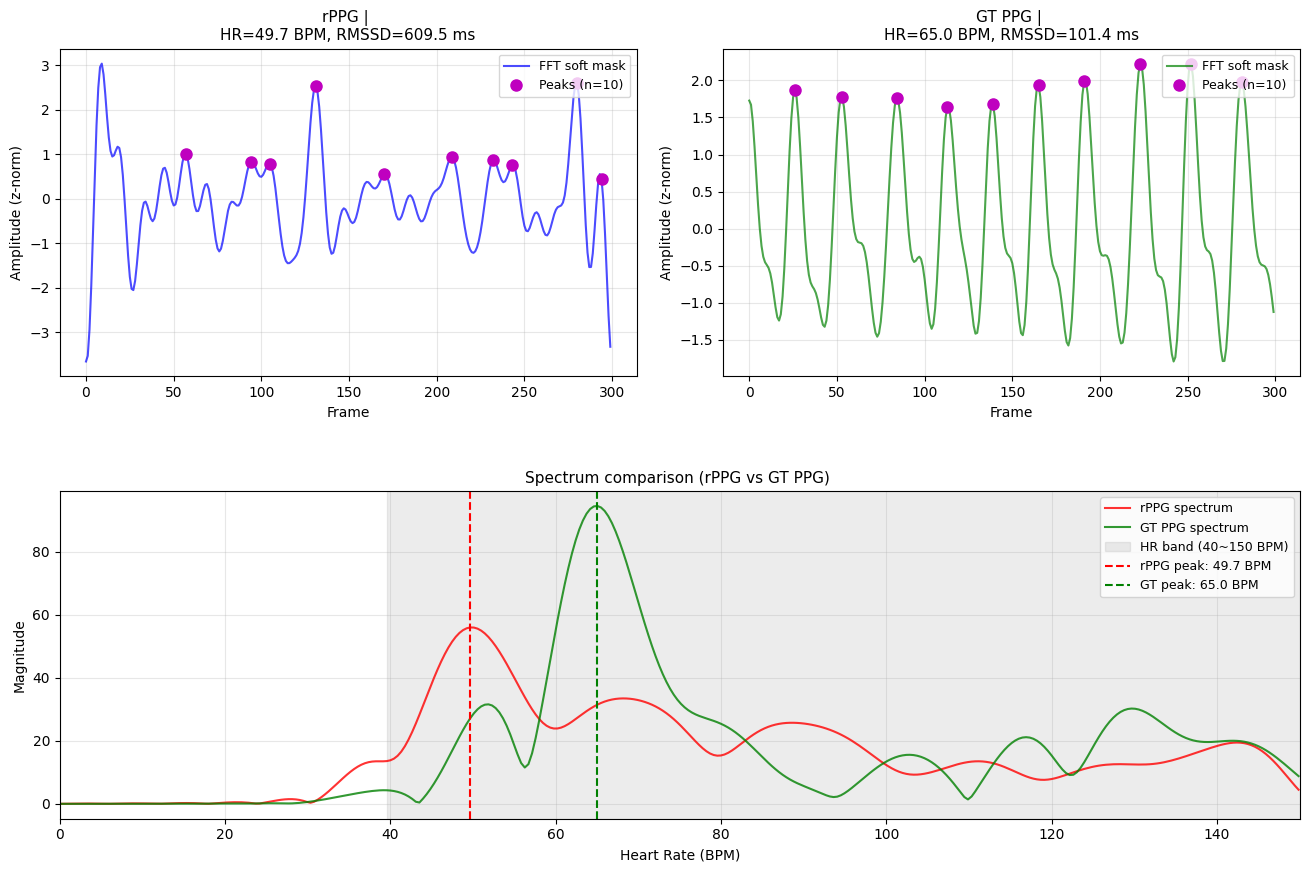


Metrics summary (10s window, nfft=4096)
BPM bin resolution: 0.439 BPM
HR (FFT+harmonic) | rPPG: 49.66 BPM, GT: 65.04 BPM, Error: 15.38 BPM
RMSSD (peak-based) | rPPG: 609.53 ms, GT: 101.38 ms, Ratio: 6.01x
# peaks (time-domain) | rPPG: 10, GT: 10


In [31]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy import signal
from scipy.signal import butter, filtfilt
from scipy.fft import fft

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/nirpdriving/LOSO_driving_withregis_ncorshift/fold_4/best_model.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_driving_withoutoutlier_len300_gtsubjectznorm'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 및 추론 (10초 = 300프레임 단일 윈도우) =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[9:10]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

window_idx = 5

input_vid, gt_ppg, _ = valid_dataset[window_idx]
input_vid = input_vid.unsqueeze(0).to(device)
with torch.no_grad():
    rppg = model(input_vid)

rppg_np   = rppg.cpu().numpy().flatten().astype(np.float64)
gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)).astype(np.float64)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ===== Bandpass (soft FFT mask) =====
def bandpass_fft_soft(sig, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(sig, np.ndarray)
    if is_numpy:
        sig = torch.tensor(sig, dtype=torch.float32)
    N = sig.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(sig.device)
    fft_signal = torch.fft.rfft(sig)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ===== Zero-padding FFT 기반 HR + PSD (Contrast-Phys+ 스타일) =====
def hr_fft(sig, fs, harmonics_removal=False, lowcut=0.66, highcut=2.5, nfft=None):
    """
    Zero-padding FFT로 HR 추정. PSD plot용 spectrum과 BPM 축도 함께 반환.
    Returns:
        hr      : 추정 HR (BPM)
        sig_f   : original magnitude spectrum (band masking 전 — plot용)
        x_hr    : BPM 단위 frequency 축
        peak_bpm: HR band 내 dominant peak BPM (vline용)
    """
    sig = sig.reshape(-1)
    N = sig.shape[0]
    sig = sig * signal.windows.hann(N)  # spectral leakage 감소
    
    # zero-padding: 기본 4096 (10초 @ 30fps → 300pt → 4096pt = ~13.6x oversampling)
    # → bin resolution 0.1 Hz(6 BPM) → 30/4096 Hz ≈ 0.44 BPM
    if nfft is None:
        nfft = max(4096, N)
    
    sig_f = np.abs(fft(sig, n=nfft))
    
    # HR band index
    low_idx  = np.round(lowcut  / fs * nfft).astype('int')
    high_idx = np.round(highcut / fs * nfft).astype('int')
    
    # plot용 원본 보존, peak 찾기용 masked
    sig_f_original = sig_f.copy()
    sig_f_masked   = sig_f.copy()
    sig_f_masked[:low_idx]  = 0
    sig_f_masked[high_idx:] = 0
    
    # peak 검출
    peak_idx, _ = signal.find_peaks(sig_f_masked)
    x_hr = np.arange(nfft) / nfft * fs * 60  # BPM axis
    
    if len(peak_idx) == 0:
        return np.nan, sig_f_original, x_hr, np.nan
    
    if len(peak_idx) == 1:
        hr = peak_idx[0] / nfft * fs * 60
        return hr, sig_f_original, x_hr, hr
    
    # 상위 2개 peak으로 harmonic 판별
    sort_idx = np.argsort(sig_f_masked[peak_idx])[::-1]
    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]
    hr1 = peak_idx1 / nfft * fs * 60
    hr2 = peak_idx2 / nfft * fs * 60
    
    if harmonics_removal:
        # hr1이 hr2의 2배(2차 harmonic)에 가까우면 hr2(fundamental)가 진짜
        if np.abs(hr1 - 2 * hr2) < 10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1
    
    return hr, sig_f_original, x_hr, hr


# ===== peak detection (time-domain plot용, RMSSD 계산용) =====
def compute_rmssd_only(sig, fs=30):
    """time-domain peak detection으로 RMSSD만 계산. HR은 별도로 FFT 기반 사용."""
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 3:
            return None, peaks
        ibi_ms = (peaks[1:] - peaks[:-1]) / fs * 1000
        d = np.diff(ibi_ms)
        return {
            'rmssd_ms':  np.sqrt(np.mean(d**2)),
            'num_peaks': len(peaks),
        }, peaks
    except Exception as e:
        print(f"⚠️ peak detection failed: {e}")
        return None, np.array([])


# ===== 필터 적용 + z-norm =====
fs = 30
NFFT = 4096  # zero-padding bin 수

rppg_fft = bandpass_fft_soft(rppg_np, fs=fs)
rppg_fft = (rppg_fft - np.mean(rppg_fft)) / np.std(rppg_fft)
gt_use   = gt_ppg_np.copy()

# ===== HR (FFT 기반) =====
hr_rppg, spec_rppg, bpm_axis_rppg, peak_bpm_rppg = hr_fft(rppg_fft, fs=fs, nfft=NFFT)
hr_gt,   spec_gt,   bpm_axis_gt,   peak_bpm_gt   = hr_fft(gt_use,   fs=fs, nfft=NFFT)

# ===== RMSSD (peak detection 기반) =====
rppg_rmssd_info, rppg_peaks = compute_rmssd_only(rppg_fft, fs=fs)
gt_rmssd_info,   gt_peaks   = compute_rmssd_only(gt_use,   fs=fs)

rppg_rmssd = rppg_rmssd_info['rmssd_ms'] if rppg_rmssd_info else np.nan
gt_rmssd   = gt_rmssd_info['rmssd_ms']   if gt_rmssd_info   else np.nan


# ===== 시각화 =====
frames = np.arange(len(rppg_fft))

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.15)

# (0, 0): rPPG time domain + peaks (RMSSD용 marker)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(frames, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
if len(rppg_peaks) > 0:
    ax1.plot(rppg_peaks, rppg_fft[rppg_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(rppg_peaks)})')
title = f'rPPG | \nHR={hr_rppg:.1f} BPM, RMSSD={rppg_rmssd:.1f} ms'
ax1.set_title(title, fontsize=11)
ax1.set_xlabel('Frame'); ax1.set_ylabel('Amplitude (z-norm)')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# (0, 1): GT time domain + peaks
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(frames, gt_use, 'g-', alpha=0.7, label='FFT soft mask')
if len(gt_peaks) > 0:
    ax2.plot(gt_peaks, gt_use[gt_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(gt_peaks)})')
title = f'GT PPG | \nHR={hr_gt:.1f} BPM, RMSSD={gt_rmssd:.1f} ms'
ax2.set_title(title, fontsize=11)
ax2.set_xlabel('Frame'); ax2.set_ylabel('Amplitude (z-norm)')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# (1, :): PSD (zero-padded) overlay - x축 BPM
ax3 = fig.add_subplot(gs[1, :])
# HR band 범위만 표시 (0~150 BPM 정도)
plot_mask = bpm_axis_rppg <= 150
ax3.plot(bpm_axis_rppg[plot_mask], spec_rppg[plot_mask],
         color='red',   label='rPPG spectrum', alpha=0.8)
ax3.plot(bpm_axis_gt[plot_mask],   spec_gt[plot_mask],
         color='green', label='GT PPG spectrum', alpha=0.8)
ax3.axvspan(0.66*60, 2.5*60, color='gray', alpha=0.15,
            label='HR band (40~150 BPM)')
ax3.axvline(hr_rppg, color='red',   linestyle='--', linewidth=1.5,
            label=f'rPPG peak: {hr_rppg:.1f} BPM')
ax3.axvline(hr_gt,   color='green', linestyle='--', linewidth=1.5,
            label=f'GT peak: {hr_gt:.1f} BPM')

ax3.set_xlim(0, 150)
ax3.set_title(f'Spectrum comparison (rPPG vs GT PPG) '
              , fontsize=11)
ax3.set_xlabel('Heart Rate (BPM)')
ax3.set_ylabel('Magnitude')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(pic_save_dir, 'time_freq_domain_10s_zeropad.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
print(f"\n💾 Saved: {save_path}")
plt.show()


# ===== 메트릭 출력 =====
print("\n" + "="*60)
print(f"Metrics summary (10s window, nfft={NFFT})")
print(f"BPM bin resolution: {fs/NFFT*60:.3f} BPM")
print("="*60)
print(f"HR (FFT+harmonic) | rPPG: {hr_rppg:.2f} BPM, GT: {hr_gt:.2f} BPM, "
      f"Error: {abs(hr_rppg - hr_gt):.2f} BPM")
print(f"RMSSD (peak-based) | rPPG: {rppg_rmssd:.2f} ms, GT: {gt_rmssd:.2f} ms, "
      f"Ratio: {rppg_rmssd/gt_rmssd:.2f}x")
print(f"# peaks (time-domain) | rPPG: {len(rppg_peaks)}, GT: {len(gt_peaks)}")

In [17]:
# ===== GT의 peak detection 기반 HR이 특정 BPM 근처인 윈도우 찾기 =====
print("\n" + "="*60)
print("Searching windows with GT peak-based HR near target BPM...")
print("="*60)

target_bpm = 71.6
tolerance = 1.0  # ±1 BPM 이내

candidates = []

for i in range(len(valid_dataset)):
    try:
        _, gt_ppg_i, _ = valid_dataset[i]
        gt_i_np = (gt_ppg_i.numpy() if hasattr(gt_ppg_i, 'numpy')
                   else np.asarray(gt_ppg_i)).astype(np.float64)

        # GT peak detection
        clean = nk.ppg_clean(gt_i_np.copy(), sampling_rate=fs, method='elgendi')
        gt_peaks_i = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        
        if len(gt_peaks_i) < 3:
            continue
        
        # peak 간격 → 평균 IBI → HR
        ibi_ms = np.diff(gt_peaks_i) / fs * 1000   # ms
        gt_peak_hr = 60000.0 / np.mean(ibi_ms)     # BPM
        
        # target 근처인지 확인
        if abs(gt_peak_hr - target_bpm) <= tolerance:
            candidates.append({
                'idx': i,
                'gt_peak_hr': gt_peak_hr,
                'num_peaks': len(gt_peaks_i),
                'mean_ibi_ms': np.mean(ibi_ms),
            })
    except Exception as e:
        print(f"  ⚠️ window {i} failed: {e}")
        continue

# 결과 출력
print(f"\nTarget: GT peak-based HR = {target_bpm} ± {tolerance} BPM")
print(f"Found {len(candidates)} matching windows")
print("-"*70)

if candidates:
    candidates.sort(key=lambda x: abs(x['gt_peak_hr'] - target_bpm))
    
    print(f"{'idx':<6}{'GT peak HR (BPM)':<20}{'mean IBI (ms)':<18}{'# peaks':<10}")
    print("-"*70)
    for c in candidates:
        print(f"{c['idx']:<6}{c['gt_peak_hr']:<20.2f}"
              f"{c['mean_ibi_ms']:<18.1f}{c['num_peaks']:<10}")
    print("-"*70)
    print(f"\n📌 가장 가까운 윈도우: window_idx = {candidates[0]['idx']}")
    print(f"   GT peak HR = {candidates[0]['gt_peak_hr']:.2f} BPM "
          f"(target 차이: {abs(candidates[0]['gt_peak_hr'] - target_bpm):.3f} BPM)")
else:
    print(f"⚠️ {target_bpm} ± {tolerance} BPM 범위에 해당하는 윈도우가 없습니다.")
    print("   tolerance를 늘려보세요.")
print("="*60)


Searching windows with GT peak-based HR near target BPM...

Target: GT peak-based HR = 71.6 ± 1.0 BPM
Found 14 matching windows
----------------------------------------------------------------------
idx   GT peak HR (BPM)    mean IBI (ms)     # peaks   
----------------------------------------------------------------------
29    71.74               836.4             12        
6     71.43               840.0             11        
35    71.22               842.4             12        
9     71.22               842.4             12        
14    72.00               833.3             12        
15    72.00               833.3             12        
85    72.00               833.3             11        
34    71.15               843.3             11        
13    70.97               845.5             12        
65    72.26               830.3             12        
16    72.26               830.3             12        
80    70.87               846.7             11        
28    72.53   

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300/final_dataset_C003_20250702.h5']
rPPG: (300,), GT: (300,)


/tmp/ipykernel_1995636/3607963403.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



💾 Saved: /home/son/orientation-uv-rppg/data/pics/time_freq_domain_10s_zeropad.png


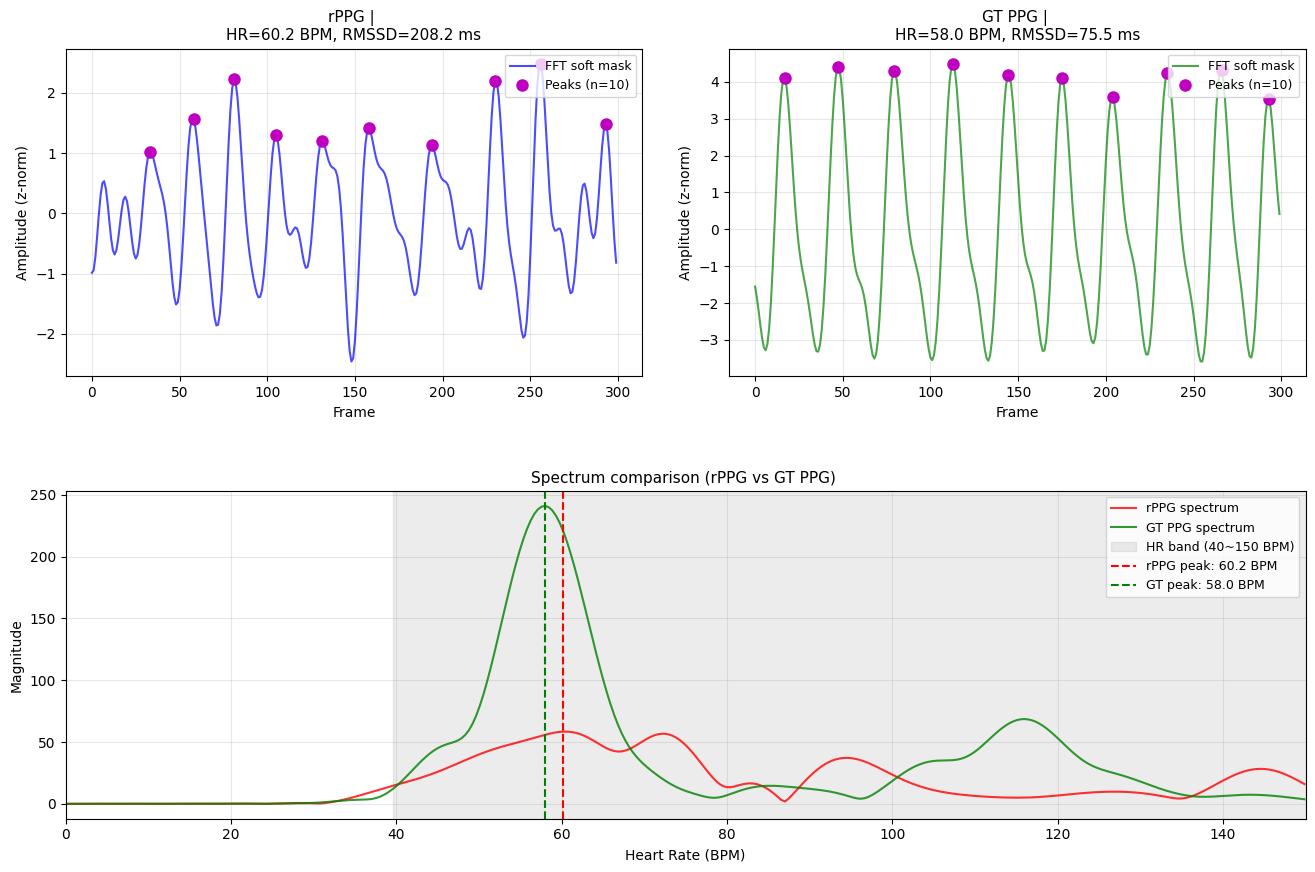


Metrics summary (10s window, nfft=4096)
BPM bin resolution: 0.439 BPM
HR (FFT+harmonic) | rPPG: 60.21 BPM, GT: 58.01 BPM, Error: 2.20 BPM
RMSSD (peak-based) | rPPG: 208.17 ms, GT: 75.46 ms, Ratio: 2.76x
# peaks (time-domain) | rPPG: 10, GT: 10


In [24]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy import signal
from scipy.signal import butter, filtfilt
from scipy.fft import fft

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithregis_13out_and_znorm/ncor_withoutshift/0.0001_epoch:67_MAE: 9.93.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 및 추론 (10초 = 300프레임 단일 윈도우) =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[14:]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

window_idx = 0

input_vid, gt_ppg, _ = valid_dataset[window_idx]
input_vid = input_vid.unsqueeze(0).to(device)
with torch.no_grad():
    rppg = model(input_vid)

rppg_np   = rppg.cpu().numpy().flatten().astype(np.float64)
gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)).astype(np.float64)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ===== Bandpass (soft FFT mask) =====
def bandpass_fft_soft(sig, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(sig, np.ndarray)
    if is_numpy:
        sig = torch.tensor(sig, dtype=torch.float32)
    N = sig.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(sig.device)
    fft_signal = torch.fft.rfft(sig)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ===== Zero-padding FFT 기반 HR + PSD (Contrast-Phys+ 스타일) =====
def hr_fft(sig, fs, harmonics_removal=False, lowcut=0.66, highcut=2.5, nfft=None):
    """
    Zero-padding FFT로 HR 추정. PSD plot용 spectrum과 BPM 축도 함께 반환.
    Returns:
        hr      : 추정 HR (BPM)
        sig_f   : original magnitude spectrum (band masking 전 — plot용)
        x_hr    : BPM 단위 frequency 축
        peak_bpm: HR band 내 dominant peak BPM (vline용)
    """
    sig = sig.reshape(-1)
    N = sig.shape[0]
    sig = sig * signal.windows.hann(N)  # spectral leakage 감소
    
    # zero-padding: 기본 4096 (10초 @ 30fps → 300pt → 4096pt = ~13.6x oversampling)
    # → bin resolution 0.1 Hz(6 BPM) → 30/4096 Hz ≈ 0.44 BPM
    if nfft is None:
        nfft = max(4096, N)
    
    sig_f = np.abs(fft(sig, n=nfft))
    
    # HR band index
    low_idx  = np.round(lowcut  / fs * nfft).astype('int')
    high_idx = np.round(highcut / fs * nfft).astype('int')
    
    # plot용 원본 보존, peak 찾기용 masked
    sig_f_original = sig_f.copy()
    sig_f_masked   = sig_f.copy()
    sig_f_masked[:low_idx]  = 0
    sig_f_masked[high_idx:] = 0
    
    # peak 검출
    peak_idx, _ = signal.find_peaks(sig_f_masked)
    x_hr = np.arange(nfft) / nfft * fs * 60  # BPM axis
    
    if len(peak_idx) == 0:
        return np.nan, sig_f_original, x_hr, np.nan
    
    if len(peak_idx) == 1:
        hr = peak_idx[0] / nfft * fs * 60
        return hr, sig_f_original, x_hr, hr
    
    # 상위 2개 peak으로 harmonic 판별
    sort_idx = np.argsort(sig_f_masked[peak_idx])[::-1]
    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]
    hr1 = peak_idx1 / nfft * fs * 60
    hr2 = peak_idx2 / nfft * fs * 60
    
    if harmonics_removal:
        # hr1이 hr2의 2배(2차 harmonic)에 가까우면 hr2(fundamental)가 진짜
        if np.abs(hr1 - 2 * hr2) < 10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1
    
    return hr, sig_f_original, x_hr, hr


# ===== peak detection (time-domain plot용, RMSSD 계산용) =====
def compute_rmssd_only(sig, fs=30):
    """time-domain peak detection으로 RMSSD만 계산. HR은 별도로 FFT 기반 사용."""
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 3:
            return None, peaks
        ibi_ms = (peaks[1:] - peaks[:-1]) / fs * 1000
        d = np.diff(ibi_ms)
        return {
            'rmssd_ms':  np.sqrt(np.mean(d**2)),
            'num_peaks': len(peaks),
        }, peaks
    except Exception as e:
        print(f"⚠️ peak detection failed: {e}")
        return None, np.array([])


# ===== 필터 적용 + z-norm =====
fs = 30
NFFT = 4096  # zero-padding bin 수

rppg_fft = bandpass_fft_soft(rppg_np, fs=fs)
rppg_fft = (rppg_fft - np.mean(rppg_fft)) / np.std(rppg_fft)
gt_use   = gt_ppg_np.copy()

# ===== HR (FFT 기반) =====
hr_rppg, spec_rppg, bpm_axis_rppg, peak_bpm_rppg = hr_fft(rppg_fft, fs=fs, nfft=NFFT)
hr_gt,   spec_gt,   bpm_axis_gt,   peak_bpm_gt   = hr_fft(gt_use,   fs=fs, nfft=NFFT)

# ===== RMSSD (peak detection 기반) =====
rppg_rmssd_info, rppg_peaks = compute_rmssd_only(rppg_fft, fs=fs)
gt_rmssd_info,   gt_peaks   = compute_rmssd_only(gt_use,   fs=fs)

rppg_rmssd = rppg_rmssd_info['rmssd_ms'] if rppg_rmssd_info else np.nan
gt_rmssd   = gt_rmssd_info['rmssd_ms']   if gt_rmssd_info   else np.nan


# ===== 시각화 =====
frames = np.arange(len(rppg_fft))

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.15)

# (0, 0): rPPG time domain + peaks (RMSSD용 marker)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(frames, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
if len(rppg_peaks) > 0:
    ax1.plot(rppg_peaks, rppg_fft[rppg_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(rppg_peaks)})')
title = f'rPPG | \nHR={hr_rppg:.1f} BPM, RMSSD={rppg_rmssd:.1f} ms'
ax1.set_title(title, fontsize=11)
ax1.set_xlabel('Frame'); ax1.set_ylabel('Amplitude (z-norm)')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# (0, 1): GT time domain + peaks
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(frames, gt_use, 'g-', alpha=0.7, label='FFT soft mask')
if len(gt_peaks) > 0:
    ax2.plot(gt_peaks, gt_use[gt_peaks], 'mo',
             markersize=8, label=f'Peaks (n={len(gt_peaks)})')
title = f'GT PPG | \nHR={hr_gt:.1f} BPM, RMSSD={gt_rmssd:.1f} ms'
ax2.set_title(title, fontsize=11)
ax2.set_xlabel('Frame'); ax2.set_ylabel('Amplitude (z-norm)')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# (1, :): PSD (zero-padded) overlay - x축 BPM
ax3 = fig.add_subplot(gs[1, :])
# HR band 범위만 표시 (0~150 BPM 정도)
plot_mask = bpm_axis_rppg <= 150
ax3.plot(bpm_axis_rppg[plot_mask], spec_rppg[plot_mask],
         color='red',   label='rPPG spectrum', alpha=0.8)
ax3.plot(bpm_axis_gt[plot_mask],   spec_gt[plot_mask],
         color='green', label='GT PPG spectrum', alpha=0.8)
ax3.axvspan(0.66*60, 2.5*60, color='gray', alpha=0.15,
            label='HR band (40~150 BPM)')
ax3.axvline(hr_rppg, color='red',   linestyle='--', linewidth=1.5,
            label=f'rPPG peak: {hr_rppg:.1f} BPM')
ax3.axvline(hr_gt,   color='green', linestyle='--', linewidth=1.5,
            label=f'GT peak: {hr_gt:.1f} BPM')

ax3.set_xlim(0, 150)
ax3.set_title(f'Spectrum comparison (rPPG vs GT PPG) '
              , fontsize=11)
ax3.set_xlabel('Heart Rate (BPM)')
ax3.set_ylabel('Magnitude')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(pic_save_dir, 'time_freq_domain_10s_zeropad.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
print(f"\n💾 Saved: {save_path}")
plt.show()


# ===== 메트릭 출력 =====
print("\n" + "="*60)
print(f"Metrics summary (10s window, nfft={NFFT})")
print(f"BPM bin resolution: {fs/NFFT*60:.3f} BPM")
print("="*60)
print(f"HR (FFT+harmonic) | rPPG: {hr_rppg:.2f} BPM, GT: {hr_gt:.2f} BPM, "
      f"Error: {abs(hr_rppg - hr_gt):.2f} BPM")
print(f"RMSSD (peak-based) | rPPG: {rppg_rmssd:.2f} ms, GT: {gt_rmssd:.2f} ms, "
      f"Ratio: {rppg_rmssd/gt_rmssd:.2f}x")
print(f"# peaks (time-domain) | rPPG: {len(rppg_peaks)}, GT: {len(gt_peaks)}")